# Задание №5 — Больничные листы
Таблица сотрудников: ФИО, месяц, дата поступления, должность, рабочие дни, средний заработок, больничные дни.

Условия: 12 записей, 3 разных месяца, 4 должности и 4 фамилии, есть сотрудники со стажем меньше 5 лет, от 5 до 8 лет и больше 8 лет.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from datetime import date

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)

## Исходная таблица

In [2]:
employees = {
    # ФИО: (дата поступления, должность, средний заработок)
    'Иванов И.И.':   ('2020-03-15', 'Инженер',    65000),  # стаж 5–8 лет
    'Петров П.П.':   ('2023-06-01', 'Бухгалтер',  55000),  # стаж < 5 лет
    'Сидорова А.В.': ('2012-09-10', 'Менеджер',   70000),  # стаж > 8 лет
    'Кузнецов Д.С.': ('2014-02-20', 'Программист', 90000), # стаж > 8 лет
}

months = ['Сентябрь', 'Октябрь', 'Ноябрь']
work_days = {'Сентябрь': 22, 'Октябрь': 23, 'Ноябрь': 20}

sick_days = {  # больничные дни: ФИО -> по месяцам
    'Иванов И.И.':   [3, 0, 5],
    'Петров П.П.':   [7, 2, 0],
    'Сидорова А.В.': [0, 10, 4],
    'Кузнецов Д.С.': [6, 1, 8],
}

rows = []
for i, month in enumerate(months):
    for fio, (start, post, salary) in employees.items():
        rows.append({
            'ФИО': fio,
            'Месяц': month,
            'Дата поступления': pd.to_datetime(start),
            'Должность': post,
            'Рабочих дней в месяце': work_days[month],
            'Средний заработок': salary,
            'Количество больничных дней': sick_days[fio][i],
        })

df = pd.DataFrame(rows)
print('Записей в таблице:', len(df))
df

Записей в таблице: 12


,ФИО,Месяц,Дата поступления,Должность,Рабочих дней в месяце,Средний заработок,Количество больничных дней
0,Иванов И.И.,Сентябрь,2020-03-15,Инженер,22,65000,3
1,Петров П.П.,Сентябрь,2023-06-01,Бухгалтер,22,55000,7
2,Сидорова А.В.,Сентябрь,2012-09-10,Менеджер,22,70000,0
3,Кузнецов Д.С.,Сентябрь,2014-02-20,Программист,22,90000,6
4,Иванов И.И.,Октябрь,2020-03-15,Инженер,23,65000,0
5,Петров П.П.,Октябрь,2023-06-01,Бухгалтер,23,55000,2
6,Сидорова А.В.,Октябрь,2012-09-10,Менеджер,23,70000,10
7,Кузнецов Д.С.,Октябрь,2014-02-20,Программист,23,90000,1
8,Иванов И.И.,Ноябрь,2020-03-15,Инженер,20,65000,5
9,Петров П.П.,Ноябрь,2023-06-01,Бухгалтер,20,55000,0


## 1. Столбец «Стаж»
Стаж — полное число лет от даты поступления до сегодняшнего дня.

In [3]:
today = pd.Timestamp(date.today())

def full_years(start):
    years = today.year - start.year
    if (today.month, today.day) < (start.month, start.day):
        years -= 1
    return years

df.insert(df.columns.get_loc('Дата поступления') + 1, 'Стаж', df['Дата поступления'].apply(full_years))
df

,ФИО,Месяц,Дата поступления,Стаж,Должность,Рабочих дней в месяце,Средний заработок,Количество больничных дней
0,Иванов И.И.,Сентябрь,2020-03-15,6,Инженер,22,65000,3
1,Петров П.П.,Сентябрь,2023-06-01,3,Бухгалтер,22,55000,7
2,Сидорова А.В.,Сентябрь,2012-09-10,14,Менеджер,22,70000,0
3,Кузнецов Д.С.,Сентябрь,2014-02-20,12,Программист,22,90000,6
4,Иванов И.И.,Октябрь,2020-03-15,6,Инженер,23,65000,0
5,Петров П.П.,Октябрь,2023-06-01,3,Бухгалтер,23,55000,2
6,Сидорова А.В.,Октябрь,2012-09-10,14,Менеджер,23,70000,10
7,Кузнецов Д.С.,Октябрь,2014-02-20,12,Программист,23,90000,1
8,Иванов И.И.,Ноябрь,2020-03-15,6,Инженер,20,65000,5
9,Петров П.П.,Ноябрь,2023-06-01,3,Бухгалтер,20,55000,0


## 2. Столбец «К оплате по б/л»
- стаж меньше 5 лет — 50% от среднего заработка;
- стаж от 5 до 8 лет — 80%;
- стаж больше 8 лет — 100%.

In [4]:
def sick_pay(row):
    if row['Стаж'] < 5:
        k = 0.5
    elif row['Стаж'] > 8:
        k = 1.0
    else:
        k = 0.8
    return row['Средний заработок'] * k

df['К оплате по б/л'] = df.apply(sick_pay, axis=1)
df

,ФИО,Месяц,Дата поступления,Стаж,Должность,Рабочих дней в месяце,Средний заработок,Количество больничных дней,К оплате по б/л
0,Иванов И.И.,Сентябрь,2020-03-15,6,Инженер,22,65000,3,52000.0
1,Петров П.П.,Сентябрь,2023-06-01,3,Бухгалтер,22,55000,7,27500.0
2,Сидорова А.В.,Сентябрь,2012-09-10,14,Менеджер,22,70000,0,70000.0
3,Кузнецов Д.С.,Сентябрь,2014-02-20,12,Программист,22,90000,6,90000.0
4,Иванов И.И.,Октябрь,2020-03-15,6,Инженер,23,65000,0,52000.0
5,Петров П.П.,Октябрь,2023-06-01,3,Бухгалтер,23,55000,2,27500.0
6,Сидорова А.В.,Октябрь,2012-09-10,14,Менеджер,23,70000,10,70000.0
7,Кузнецов Д.С.,Октябрь,2014-02-20,12,Программист,23,90000,1,90000.0
8,Иванов И.И.,Ноябрь,2020-03-15,6,Инженер,20,65000,5,52000.0
9,Петров П.П.,Ноябрь,2023-06-01,3,Бухгалтер,20,55000,0,27500.0


## 3. Общая сумма оплаты больничных листов

In [5]:
total_pay = df['К оплате по б/л'].sum()
print(f'Общая сумма оплаты по б/л: {total_pay:,.2f} руб.'.replace(',', ' '))

Общая сумма оплаты по б/л: 718 500.00 руб.


## 4. Средний стаж

In [6]:
avg_exp = df['Стаж'].mean()
print(f'Средний стаж: {avg_exp:.2f} лет')

Средний стаж: 8.75 лет


## 5. Количество сотрудников со стажем меньше 8 лет

In [7]:
less8_records = (df['Стаж'] < 8).sum()
less8_people = df.loc[df['Стаж'] < 8, 'ФИО'].nunique()
print('Записей со стажем меньше 8 лет:', less8_records)
print('Сотрудников (разных людей) со стажем меньше 8 лет:', less8_people)

Записей со стажем меньше 8 лет: 6
Сотрудников (разных людей) со стажем меньше 8 лет: 2


## 6. Минимальное и максимальное количество больничных дней

In [8]:
min_sick = df['Количество больничных дней'].min()
max_sick = df['Количество больничных дней'].max()
print('Минимальное количество больничных дней:', min_sick)
print('Максимальное количество больничных дней:', max_sick)

Минимальное количество больничных дней: 0
Максимальное количество больничных дней: 10


## 7. Среднее количество больничных дней в каждом месяце

In [9]:
avg_by_month = (df.groupby('Месяц', sort=False)['Количество больничных дней']
                  .mean()
                  .round(2)
                  .reset_index()
                  .rename(columns={'Количество больничных дней': 'Среднее кол-во больничных дней'}))
avg_by_month

,Месяц,Среднее кол-во больничных дней
0,Сентябрь,4.00
1,Октябрь,3.25
2,Ноябрь,4.25


## 8. Количество дней по больничному листу по должностям

In [10]:
by_post = (df.groupby('Должность')['Количество больничных дней']
             .sum()
             .reset_index()
             .rename(columns={'Количество больничных дней': 'Больничных дней'}))
by_post

,Должность,Больничных дней
0,Бухгалтер,9
1,Инженер,8
2,Менеджер,14
3,Программист,15


## 9. Диаграмма по таблице из п. 8

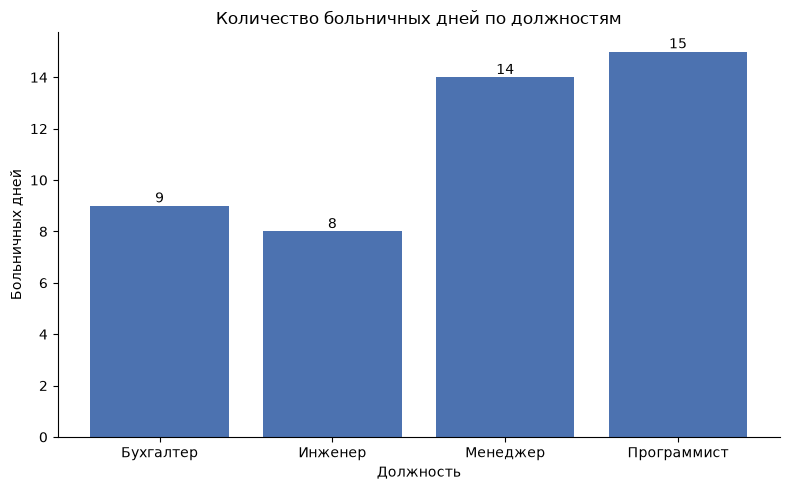

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(by_post['Должность'], by_post['Больничных дней'], color='#4C72B0')
ax.bar_label(bars)
ax.set_title('Количество больничных дней по должностям')
ax.set_xlabel('Должность')
ax.set_ylabel('Больничных дней')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()